In [3]:
from google.colab import drive
import zipfile
import os

# 1. Drive'ı Colab'a bağla (Senden izin isteyecek, kabul et)
drive.mount('/content/drive')

# DİKKAT: Aşağıdaki 'ekg_data.zip' ismini ve yolunu kendi zip dosyana göre DÜZELT!
ZIP_PATH = '/content/drive/MyDrive/eymen/ekg data.zip'
EXTRACT_PATH = '/content/ekg_data'

print("Veriler zipten çıkarılıyor, lütfen bekleyin (Bu işlem SSD hızında gerçekleşir)...")
os.makedirs(EXTRACT_PATH, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)
print("İşlem tamam! Veriler Colab GPU'su için hazır.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Veriler zipten çıkarılıyor, lütfen bekleyin (Bu işlem SSD hızında gerçekleşir)...
İşlem tamam! Veriler Colab GPU'su için hazır.


In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, ConcatDataset
import numpy as np
import os
import glob
from tqdm import tqdm
import math

# --- AYARLAR ---
# DİKKAT: Zip dosyanın içinden çıkan yapıya göre bu yolu kontrol et.
# Eğer hata verirse yolu '/content/ekg_data/düzeltilmiş_resnet_v2/processed_train' olarak değiştir.
TRAIN_DIR = '/content/ekg_data/ekg data/processed_train'

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 128
EPOCHS = 100
MASK_RATIO = 0.50

print(f"Kullanılan Cihaz: {DEVICE}")

# --- 1. VERİ YÜKLEME ---
def load_unlabeled_data(folder_path):
    files = glob.glob(os.path.join(folder_path, "*.pt"))
    datasets = []
    print(f"Self-Supervised Veriler Yükleniyor... Toplam dosya: {len(files)}")
    for f in tqdm(files):
        try:
            data = torch.load(f)
            if torch.isnan(data['X']).any(): data['X'] = torch.nan_to_num(data['X'], nan=0.0)
            datasets.append(TensorDataset(data['X']))
        except: pass
    return ConcatDataset(datasets)

print("Veriler RAM'e alınıyor...")
train_dataset = load_unlabeled_data(TRAIN_DIR)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

# --- 2. AKILLI MİMARİ: CONFORMER-MAE ---
class Conformer_MAE(nn.Module):
    def __init__(self, in_chans=12, embed_dim=128, depth=4, heads=4):
        super().__init__()

        # 1. AKILLI GÖZLÜK (CNN Stem - Sinyalin özelliklerini çıkarır ve 250 parçaya böler)
        self.stem = nn.Sequential(
            nn.Conv1d(in_chans, embed_dim // 2, kernel_size=15, stride=5, padding=7),
            nn.BatchNorm1d(embed_dim // 2),
            nn.GELU(),
            nn.Conv1d(embed_dim // 2, embed_dim, kernel_size=7, stride=4, padding=3),
            nn.BatchNorm1d(embed_dim),
            nn.GELU()
        )
        self.num_patches = 250

        # 2. Positional Embedding & Mask Token
        self.pos_embed = nn.Parameter(torch.zeros(1, self.num_patches, embed_dim))
        self.mask_token = nn.Parameter(torch.zeros(1, 1, embed_dim))

        # 3. Transformer Encoder
        encoder_layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=heads, dim_feedforward=embed_dim*4, activation='gelu', batch_first=True)
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=depth)

        # 4. Decoder (Sinyali yeniden 5000 boyutuna genişleten Ters CNN)
        self.decoder_pred = nn.Sequential(
            nn.ConvTranspose1d(embed_dim, embed_dim // 2, kernel_size=7, stride=4, padding=3, output_padding=3),
            nn.GELU(),
            nn.ConvTranspose1d(embed_dim // 2, in_chans, kernel_size=15, stride=5, padding=7, output_padding=4)
        )

        self._init_weights()

    def _init_weights(self):
        nn.init.normal_(self.pos_embed, std=.02)
        nn.init.normal_(self.mask_token, std=.02)

    def forward(self, x):
        B, C, L = x.shape
        target = x.clone()

        # 1. Sinyali CNN ile anla ve küçült -> (B, 128, 250)
        features = self.stem(x)
        features = features.permute(0, 2, 1)

        # 2. Pozisyon bilgisini ekle
        features = features + self.pos_embed

        # 3. Maskeleme (%50)
        noise = torch.rand(B, self.num_patches, device=x.device)
        mask = noise < MASK_RATIO

        mask_tokens = self.mask_token.expand(B, self.num_patches, -1)
        masked_features = torch.where(mask.unsqueeze(-1), mask_tokens, features)

        # 4. Transformer'a Ver
        encoded = self.encoder(masked_features)

        # 5. Decoder ile orijinal 5000'lik sinyale geri dön
        encoded = encoded.permute(0, 2, 1)
        pred = self.decoder_pred(encoded)

        # 6. Sinyalin tamamı üzerinden Loss (Hata) hesapla
        loss = nn.functional.mse_loss(pred, target)
        return loss, pred

# --- 3. EĞİTİM DÖNGÜSÜ ---
model = Conformer_MAE().to(DEVICE)
optimizer = optim.AdamW(model.parameters(), lr=2e-3, weight_decay=0.01)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

print("\n🚀 AKILLI CONFORMER-MAE EĞİTİMİ BAŞLIYOR 🚀")

best_loss = float('inf')

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0

    loop = tqdm(train_loader, desc=f"Epoch [{epoch+1}/{EPOCHS}]")
    for (inputs,) in loop:
        inputs = inputs.to(DEVICE)

        mean = inputs.mean(dim=2, keepdim=True)
        std = inputs.std(dim=2, keepdim=True)
        inputs = (inputs - mean) / (std + 1e-5)

        optimizer.zero_grad()
        loss, _ = model(inputs)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        total_loss += loss.item()
        loop.set_postfix(loss=loss.item())

    avg_loss = total_loss / len(train_loader)
    scheduler.step()

    print(f"Epoch {epoch+1} Özet -> MSE: {avg_loss:.4f} | LR: {scheduler.get_last_lr()[0]:.6f}")

    if avg_loss < best_loss:
        best_loss = avg_loss
        # Modeli kaydet (Eğer drive bağlı değilse '/content/pretrained_ekg_brain.pth' yapabilirsin)
        torch.save(model.state_dict(), '/content/drive/MyDrive/pretrained_ekg_brain.pth')
        print(f"🏆 Yeni Rekor Beyin Kaydedildi! (Kayıp: {avg_loss:.4f})")

Kullanılan Cihaz: cuda
Veriler RAM'e alınıyor...
Self-Supervised Veriler Yükleniyor... Toplam dosya: 36


100%|██████████| 36/36 [00:15<00:00,  2.33it/s]



🚀 AKILLI CONFORMER-MAE EĞİTİMİ BAŞLIYOR 🚀


Epoch [1/100]: 100%|██████████| 433/433 [00:20<00:00, 21.30it/s, loss=0.296]


Epoch 1 Özet -> MSE: 0.3596 | LR: 0.002000
🏆 Yeni Rekor Beyin Kaydedildi! (Kayıp: 0.3596)


Epoch [2/100]: 100%|██████████| 433/433 [00:18<00:00, 22.91it/s, loss=0.279]


... (193 outputs left out)

Epoch [99/100]: 100%|██████████| 433/433 [00:18<00:00, 22.86it/s, loss=0.237]


Epoch 99 Özet -> MSE: 0.2323 | LR: 0.000000


Epoch [100/100]: 100%|██████████| 433/433 [00:18<00:00, 22.92it/s, loss=0.228]


Epoch 100 Özet -> MSE: 0.2308 | LR: 0.000000
🏆 Yeni Rekor Beyin Kaydedildi! (Kayıp: 0.2308)


In [9]:
pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 413.9/413.9 kB 33.4 MB/s eta 0:00:00


In [16]:
# --- COLAB İÇİN DÜZELTİLMİŞ YOLLAR ---
DATA_SOURCE_DIR = '/content/ekg_data/ekg data' # Boşluğa dikkat!
TRAIN_DIR = os.path.join(DATA_SOURCE_DIR, "processed_train")
BENCHMARK_DIR = os.path.join(DATA_SOURCE_DIR, "benchmark")

# Diğer yollar aynı kalacak
OUTPUT_DIR = '/content/drive/MyDrive/ekg_finetune_results'
PRETRAINED_BRAIN_PATH = '/content/drive/MyDrive/pretrained_ekg_brain.pth'

In [21]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, ConcatDataset
from sklearn.metrics import f1_score
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import os
import glob
from tqdm import tqdm
import warnings
import math
import optuna
from optuna.trial import TrialState

warnings.filterwarnings("ignore")

# --- COLAB İÇİN AYARLAR ---
# DİKKAT: Eğer verilerin direkt ekg_data içindeyse yolu '/content/ekg_data' yap.
# Eğer zipin içinden 'düzeltilmiş_resnet_v2' diye bir klasör çıktıysa aşağıdaki gibi kalsın.
DATA_SOURCE_DIR = '/content/ekg_data/ekg data/'
TRAIN_DIR = os.path.join(DATA_SOURCE_DIR, "processed_train")
BENCHMARK_DIR = os.path.join(DATA_SOURCE_DIR, "benchmark")

# Sonuçları (Modeli ve Optuna Veritabanını) kaybetmemek için DOĞRUDAN DRIVE'A KAYDEDİYORUZ
OUTPUT_DIR = '/content/drive/MyDrive/ekg_finetune_results'
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Kendi eğittiğin uzman beynin yolu
PRETRAINED_BRAIN_PATH = '/content/drive/MyDrive/pretrained_ekg_brain.pth'

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 128 # Colab GPU'su güçlü olduğu için 128'e çıkardık, fırtına gibi essin
NUM_CLASSES = 3

# --- 1. ÖZEL KAYIP FONKSİYONU: FOCAL LOSS ---
class FocalLoss(nn.Module):
    def __init__(self, weight=None, gamma=2.0):
        super(FocalLoss, self).__init__()
        self.weight = weight
        self.gamma = gamma

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, weight=self.weight, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss
        return focal_loss.mean()

# --- 2. MİMARİ: TRANSFER LEARNING (CONFORMER CLASSIFIER) ---
class Conformer_Classifier(nn.Module):
    def __init__(self, in_chans=12, embed_dim=128, depth=4, heads=4, dropout=0.2):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv1d(in_chans, embed_dim // 2, kernel_size=15, stride=5, padding=7),
            nn.BatchNorm1d(embed_dim // 2),
            nn.GELU(),
            nn.Conv1d(embed_dim // 2, embed_dim, kernel_size=7, stride=4, padding=3),
            nn.BatchNorm1d(embed_dim),
            nn.GELU()
        )
        self.num_patches = 250
        self.pos_embed = nn.Parameter(torch.zeros(1, self.num_patches, embed_dim))

        encoder_layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=heads, dim_feedforward=embed_dim*4, dropout=dropout, activation='gelu', batch_first=True)
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=depth)

        self.fc = nn.Sequential(
            nn.Linear(embed_dim, embed_dim // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(embed_dim // 2, NUM_CLASSES)
        )

    def forward(self, x):
        features = self.stem(x)
        features = features.permute(0, 2, 1)
        features = features + self.pos_embed

        encoded = self.encoder(features)

        pooled = torch.mean(encoded, dim=1)
        out = self.fc(pooled)
        return out

# --- 3. VERİ YÜKLEME VE AĞIRLIKLAR ---
def load_data(folder_path, prefix):
    files = glob.glob(os.path.join(folder_path, f"{prefix}*.pt"))
    datasets = []
    for f in files:
        try:
            data = torch.load(f)
            if torch.isnan(data['X']).any(): data['X'] = torch.nan_to_num(data['X'], nan=0.0)
            if len(data['y']) > 0: datasets.append(TensorDataset(data['X'], data['y']))
        except: pass
    return ConcatDataset(datasets)

print("Veriler Yükleniyor...")
train_dataset = load_data(TRAIN_DIR, "train_part")
val_dataset = load_data(BENCHMARK_DIR, "val_part")

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

all_y = [ds.tensors[1].numpy() for ds in train_dataset.datasets]
all_y = np.concatenate(all_y)
class_weights = compute_class_weight('balanced', classes=np.unique(all_y), y=all_y)
class_weights[1] *= 1.5
weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)

# --- 4. BEYİN YÜKLEME ---
def load_pretrained_weights(model, pretrained_path):
    if not os.path.exists(pretrained_path):
        raise FileNotFoundError(f"BEYİN BULUNAMADI! Yol: {pretrained_path}")

    state_dict = torch.load(pretrained_path, map_location=DEVICE)
    model_dict = model.state_dict()

    pretrained_dict = {k: v for k, v in state_dict.items() if k in model_dict and v.shape == model_dict[k].shape}

    model_dict.update(pretrained_dict)
    model.load_state_dict(model_dict)
    return model

# --- 5. OPTUNA ---
def objective(trial):
    dropout = trial.suggest_float("dropout", 0.1, 0.5)
    lr = trial.suggest_float("lr", 1e-5, 5e-4, log=True)

    model = Conformer_Classifier(dropout=dropout).to(DEVICE)
    model = load_pretrained_weights(model, PRETRAINED_BRAIN_PATH)

    criterion = FocalLoss(weight=weights_tensor, gamma=2.0)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)

    EPOCHS = 8
    best_val_f1 = 0.0

    for epoch in range(EPOCHS):
        model.train()
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            mean = inputs.mean(dim=2, keepdim=True)
            std = inputs.std(dim=2, keepdim=True)
            inputs = (inputs - mean) / (std + 1e-5)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        model.eval()
        all_preds, all_targets = [], []
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
                mean = inputs.mean(dim=2, keepdim=True)
                std = inputs.std(dim=2, keepdim=True)
                inputs = (inputs - mean) / (std + 1e-5)
                outputs = model(inputs)
                _, preds = torch.max(outputs, 1)
                all_preds.extend(preds.cpu().numpy())
                all_targets.extend(targets.cpu().numpy())

        val_f1 = f1_score(all_targets, all_preds, average='macro')

        trial.report(val_f1, epoch)
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            temp_path = os.path.join(OUTPUT_DIR, f"finetune_trial_{trial.number}_best.pth")
            torch.save(model.state_dict(), temp_path)

    return best_val_f1

if __name__ == "__main__":
    print("🚀 TRANSFER LEARNING + OPTUNA (COLAB) BAŞLIYOR...")

    db_path = os.path.join(OUTPUT_DIR, "conformer_finetune.db")
    study = optuna.create_study(
        direction="maximize",
        study_name="ekg_finetune_colab",
        storage=f"sqlite:///{db_path}",
        load_if_exists=True,
        pruner=optuna.pruners.MedianPruner(n_startup_trials=2, n_warmup_steps=3, interval_steps=1)
    )

    study.optimize(objective, n_trials=15)

    print("\n🏆 İNCE AYAR BİTTİ! İŞTE TRANSFER LEARNING ŞAMPİYONU:")
    best_trial = study.best_trial
    print(f"En Yüksek F1 Skoru: {best_trial.value:.4f}")
    for key, value in best_trial.params.items():
        print(f"    {key}: {value}")

    import shutil
    best_temp_model = os.path.join(OUTPUT_DIR, f"finetune_trial_{best_trial.number}_best.pth")
    final_model_path = os.path.join(OUTPUT_DIR, "BEST_FINETUNED_CONFORMER.pth")
    if os.path.exists(best_temp_model):
        shutil.copy(best_temp_model, final_model_path)
        print(f"\n✅ Nihai Şampiyon Model Drive'a kaydedildi: {final_model_path}")

    for f in glob.glob(os.path.join(OUTPUT_DIR, "finetune_trial_*_best.pth")):
        if f != best_temp_model:
            os.remove(f)

Veriler Yükleniyor...
🚀 TRANSFER LEARNING + OPTUNA (COLAB) BAŞLIYOR...


[I 2026-03-07 11:37:23,221] A new study created in RDB with name: ekg_finetune_colab
[I 2026-03-07 11:39:32,781] Trial 0 finished with value: 0.5367974142346599 and parameters: {'dropout': 0.10268863814669112, 'lr': 1.430134996559959e-05}. Best is trial 0 with value: 0.5367974142346599.
[I 2026-03-07 11:41:42,420] Trial 1 finished with value: 0.5330527711711358 and parameters: {'dropout': 0.19576077499906241, 'lr': 1.2013638685138243e-05}. Best is trial 0 with value: 0.5367974142346599.
[I 2026-03-07 11:42:47,201] Trial 2 pruned. 
[I 2026-03-07 11:43:51,834] Trial 3 pruned. 
[I 2026-03-07 11:46:01,244] Trial 4 finished with value: 0.7156428297824995 and parameters: {'dropout': 0.24175723517606684, 'lr': 0.0003082751222135671}. Best is trial 4 with value: 0.7156428297824995.
[I 2026-03-07 11:48:10,718] Trial 5 finished with value: 0.6469112664725197 and parameters: {'dropout': 0.22825209833486193, 'lr': 3.140903184310884e-05}. Best is trial 4 with value: 0.7156428297824995.
[I 2026-03-0


🏆 İNCE AYAR BİTTİ! İŞTE TRANSFER LEARNING ŞAMPİYONU:
En Yüksek F1 Skoru: 0.7156
    dropout: 0.24175723517606684
    lr: 0.0003082751222135671

✅ Nihai Şampiyon Model Drive'a kaydedildi: /content/drive/MyDrive/ekg_finetune_results/BEST_FINETUNED_CONFORMER.pth


BURADA ŞUANA KADAR EN SAF VERİ KULLANILDI AMA AŞAĞIDAKİ KODDA DAHA FAZLA ÖRNEK İÇEREN NATURAL VE AUGMENTED VERİ SETİYLE DENENECEK


In [22]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, ConcatDataset, Dataset
from sklearn.metrics import f1_score
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import os
import glob
from tqdm import tqdm
import warnings
import math
import optuna

warnings.filterwarnings("ignore")

# =====================================================================
# --- COLAB İÇİN ÖZEL AYARLAR ---
# =====================================================================
DATA_SOURCE_DIR = '/content/ekg_data/ekg data' # Boşluklu klasör adı sorunu çözüldü
TRAIN_DIR = os.path.join(DATA_SOURCE_DIR, "processed_train")
BENCHMARK_DIR = os.path.join(DATA_SOURCE_DIR, "benchmark")

# Sonuçlar doğrudan Google Drive'a kaydedilecek
OUTPUT_DIR = '/content/drive/MyDrive/ekg_finetune_results'
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Eğittiğimiz uzman MAE beyni
PRETRAINED_BRAIN_PATH = '/content/drive/MyDrive/pretrained_ekg_brain.pth'

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 128 # Colab GPU'su güçlü olduğu için 128'de tutuyoruz
NUM_CLASSES = 3

# =====================================================================
# --- YENİ: DİNAMİK VERİ ARTIRMA (ON-THE-FLY AUGMENTATION) ---
# =====================================================================
class AugmentedECGDataset(Dataset):
    def __init__(self, base_dataset, transform=False):
        self.base = base_dataset
        self.transform = transform

    def __len__(self):
        return len(self.base)

    def __getitem__(self, idx):
        x, y = self.base[idx]
        x = x.clone() # Orijinal veriyi bozmamak için kopyalıyoruz

        # Sadece eğitim sırasında %50 ihtimalle sinyali boz/değiştir
        if self.transform:
            if torch.rand(1).item() < 0.5: # Noise (Gürültü)
                noise = torch.randn_like(x) * 0.01
                x = x + noise
            if torch.rand(1).item() < 0.5: # Scale (Ölçeklendirme)
                scale = torch.empty(1).uniform_(0.9, 1.1).item()
                x = x * scale

        return x, y

# =====================================================================
# --- MİMARİ VE KAYIP FONKSİYONU ---
# =====================================================================
class FocalLoss(nn.Module):
    def __init__(self, weight=None, gamma=2.0):
        super(FocalLoss, self).__init__()
        self.weight = weight
        self.gamma = gamma

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, weight=self.weight, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss
        return focal_loss.mean()

class Conformer_Classifier(nn.Module):
    def __init__(self, in_chans=12, embed_dim=128, depth=4, heads=4, dropout=0.2):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv1d(in_chans, embed_dim // 2, kernel_size=15, stride=5, padding=7),
            nn.BatchNorm1d(embed_dim // 2), nn.GELU(),
            nn.Conv1d(embed_dim // 2, embed_dim, kernel_size=7, stride=4, padding=3),
            nn.BatchNorm1d(embed_dim), nn.GELU()
        )
        self.num_patches = 250
        self.pos_embed = nn.Parameter(torch.zeros(1, self.num_patches, embed_dim))

        encoder_layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=heads, dim_feedforward=embed_dim*4, dropout=dropout, activation='gelu', batch_first=True)
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=depth)

        self.fc = nn.Sequential(
            nn.Linear(embed_dim, embed_dim // 2), nn.GELU(),
            nn.Dropout(dropout), nn.Linear(embed_dim // 2, NUM_CLASSES)
        )

    def forward(self, x):
        features = self.stem(x)
        features = features.permute(0, 2, 1) + self.pos_embed
        encoded = self.encoder(features)
        return self.fc(torch.mean(encoded, dim=1))

def load_base_data(folder_path, prefix):
    files = glob.glob(os.path.join(folder_path, f"{prefix}*.pt"))
    datasets = []
    for f in files:
        try:
            data = torch.load(f)
            if torch.isnan(data['X']).any(): data['X'] = torch.nan_to_num(data['X'], nan=0.0)
            if len(data['y']) > 0: datasets.append(TensorDataset(data['X'], data['y']))
        except: pass
    return ConcatDataset(datasets)

print("Veriler RAM'e Yükleniyor...")
base_train = load_base_data(TRAIN_DIR, "train_part")
base_val = load_base_data(BENCHMARK_DIR, "val_part")

# Gürültü SADECE Eğitim (Train) setine uygulanır! Benchmark saf kalır.
train_dataset = AugmentedECGDataset(base_train, transform=True)
val_dataset = AugmentedECGDataset(base_val, transform=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

all_y = [ds.tensors[1].numpy() for ds in base_train.datasets]
all_y = np.concatenate(all_y)
class_weights = compute_class_weight('balanced', classes=np.unique(all_y), y=all_y)
class_weights[1] *= 1.5 # İletim sınıfına ekstra odak
weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)

def load_pretrained_weights(model, pretrained_path):
    state_dict = torch.load(pretrained_path, map_location=DEVICE)
    model_dict = model.state_dict()
    pretrained_dict = {k: v for k, v in state_dict.items() if k in model_dict and v.shape == model_dict[k].shape}
    model_dict.update(pretrained_dict)
    model.load_state_dict(model_dict)
    return model

# =====================================================================
# --- OPTUNA HEDEF FONKSİYONU ---
# =====================================================================
def objective(trial):
    dropout = trial.suggest_float("dropout", 0.1, 0.5)
    lr = trial.suggest_float("lr", 1e-5, 5e-4, log=True)

    model = Conformer_Classifier(dropout=dropout).to(DEVICE)
    model = load_pretrained_weights(model, PRETRAINED_BRAIN_PATH)

    criterion = FocalLoss(weight=weights_tensor, gamma=2.0)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)

    EPOCHS = 8
    best_val_f1 = 0.0

    for epoch in range(EPOCHS):
        model.train()
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            mean = inputs.mean(dim=2, keepdim=True)
            std = inputs.std(dim=2, keepdim=True)
            inputs = (inputs - mean) / (std + 1e-5)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        model.eval()
        all_preds, all_targets = [], []
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
                mean = inputs.mean(dim=2, keepdim=True)
                std = inputs.std(dim=2, keepdim=True)
                inputs = (inputs - mean) / (std + 1e-5)
                outputs = model(inputs)
                _, preds = torch.max(outputs, 1)
                all_preds.extend(preds.cpu().numpy())
                all_targets.extend(targets.cpu().numpy())

        # DİKKAT: Average='macro' parametresi burada Macro F1'i zorunlu kılıyor
        val_f1 = f1_score(all_targets, all_preds, average='macro')

        trial.report(val_f1, epoch)
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            temp_path = os.path.join(OUTPUT_DIR, f"finetune_aug_trial_{trial.number}_best.pth")
            torch.save(model.state_dict(), temp_path)

    return best_val_f1

if __name__ == "__main__":
    print("🚀 TEORİK SINIRLARI ZORLAYAN AUGMENTED OPTUNA (COLAB) BAŞLIYOR...")

    db_path = os.path.join(OUTPUT_DIR, "conformer_finetune_augmented.db")
    study = optuna.create_study(
        direction="maximize",
        study_name="ekg_finetune_augmented_colab",
        storage=f"sqlite:///{db_path}",
        load_if_exists=True,
        pruner=optuna.pruners.MedianPruner(n_startup_trials=2, n_warmup_steps=3, interval_steps=1)
    )

    study.optimize(objective, n_trials=15)

    print("\n🏆 İNCE AYAR BİTTİ! İŞTE AUGMENTED TRANSFER LEARNING ŞAMPİYONU:")
    best_trial = study.best_trial
    print(f"En Yüksek MACRO F1 Skoru: {best_trial.value:.4f}")
    for key, value in best_trial.params.items():
        print(f"    {key}: {value}")

    import shutil
    best_temp_model = os.path.join(OUTPUT_DIR, f"finetune_aug_trial_{best_trial.number}_best.pth")
    final_model_path = os.path.join(OUTPUT_DIR, "BEST_FINETUNED_AUGMENTED_CONFORMER.pth")
    if os.path.exists(best_temp_model):
        shutil.copy(best_temp_model, final_model_path)
        print(f"\n✅ Nihai Augmented Şampiyon Model Drive'a kaydedildi: {final_model_path}")

    for f in glob.glob(os.path.join(OUTPUT_DIR, "finetune_aug_trial_*_best.pth")):
        if f != best_temp_model:
            os.remove(f)

Veriler RAM'e Yükleniyor...
🚀 TEORİK SINIRLARI ZORLAYAN AUGMENTED OPTUNA (COLAB) BAŞLIYOR...


[I 2026-03-07 12:06:00,774] A new study created in RDB with name: ekg_finetune_augmented_colab
[I 2026-03-07 12:09:42,318] Trial 0 finished with value: 0.6934646796286023 and parameters: {'dropout': 0.1629668246122346, 'lr': 0.00012525849296203697}. Best is trial 0 with value: 0.6934646796286023.
[I 2026-03-07 12:13:24,282] Trial 1 finished with value: 0.555289227040279 and parameters: {'dropout': 0.1253839600847766, 'lr': 1.6994564288571775e-05}. Best is trial 0 with value: 0.6934646796286023.
[I 2026-03-07 12:15:15,717] Trial 2 pruned. 
[I 2026-03-07 12:18:58,816] Trial 3 finished with value: 0.6961951107337035 and parameters: {'dropout': 0.3945839655544421, 'lr': 0.00021853363360036857}. Best is trial 3 with value: 0.6961951107337035.
[I 2026-03-07 12:22:41,021] Trial 4 finished with value: 0.7006140109182892 and parameters: {'dropout': 0.25178899622859785, 'lr': 0.0003071049332213378}. Best is trial 4 with value: 0.7006140109182892.
[I 2026-03-07 12:26:22,459] Trial 5 finished with


🏆 İNCE AYAR BİTTİ! İŞTE AUGMENTED TRANSFER LEARNING ŞAMPİYONU:
En Yüksek MACRO F1 Skoru: 0.7546
    dropout: 0.2157278940843993
    lr: 0.00038820319390986

✅ Nihai Augmented Şampiyon Model Drive'a kaydedildi: /content/drive/MyDrive/ekg_finetune_results/BEST_FINETUNED_AUGMENTED_CONFORMER.pth


🧪 Conformer Şampiyonu Test Ediliyor...

📊 SINIFLANDIRMA RAPORU:
              precision    recall  f1-score   support

      Normal       0.93      0.87      0.90      2823
      İletim       0.50      0.71      0.59       250
       Ritim       0.74      0.82      0.78       764

    accuracy                           0.85      3837
   macro avg       0.72      0.80      0.75      3837
weighted avg       0.87      0.85      0.86      3837



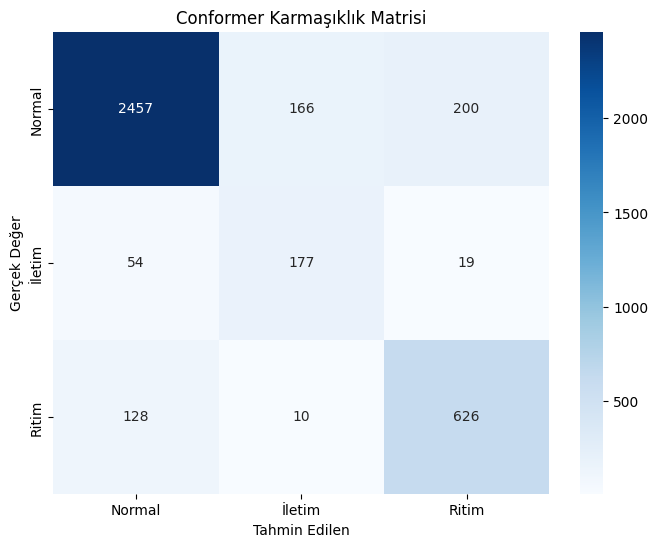

In [29]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset, ConcatDataset
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os
import glob

# --- TEST AYARLARI ---
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BENCHMARK_DIR = '/content/ekg_data/ekg data/benchmark'
MODEL_PATH = '/content/drive/MyDrive/ekg_finetune_results/BEST_FINETUNED_AUGMENTED_CONFORMER.pth'
NUM_CLASSES = 3
CLASS_NAMES = ['Normal', 'İletim', 'Ritim']

class Conformer_Classifier(nn.Module):
    def __init__(self, in_chans=12, embed_dim=128, depth=4, heads=4, dropout=0.2):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv1d(in_chans, embed_dim // 2, kernel_size=15, stride=5, padding=7),
            nn.BatchNorm1d(embed_dim // 2), nn.GELU(),
            nn.Conv1d(embed_dim // 2, embed_dim, kernel_size=7, stride=4, padding=3),
            nn.BatchNorm1d(embed_dim), nn.GELU()
        )
        self.num_patches = 250
        self.pos_embed = nn.Parameter(torch.zeros(1, self.num_patches, embed_dim))

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=heads, dim_feedforward=embed_dim*4,
            dropout=dropout, activation='gelu', batch_first=True
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=depth)

        # --- DÜZELTİLEN KISIM BURASI ---
        self.fc = nn.Sequential(
            nn.Linear(embed_dim, embed_dim // 2),
            nn.GELU(),
            nn.Dropout(dropout), # <--- Bu katman eksik olduğu için fc.3 bulunamıyordu
            nn.Linear(embed_dim // 2, NUM_CLASSES)
        )

    def forward(self, x):
        features = self.stem(x)
        features = features.permute(0, 2, 1) + self.pos_embed
        encoded = self.encoder(features)
        return self.fc(torch.mean(encoded, dim=1))

# --- TEST SÜRECİ ---
print("🧪 Conformer Şampiyonu Test Ediliyor...")

# 1. Modeli Yükle
model = Conformer_Classifier().to(DEVICE)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.eval()

# 2. Benchmark Verisini Yükle
def load_benchmark(folder_path):
    files = glob.glob(os.path.join(folder_path, "val_part*.pt"))
    datasets = []
    for f in files:
        data = torch.load(f, map_location='cpu')
        datasets.append(TensorDataset(data['X'], data['y']))
    return ConcatDataset(datasets)

test_ds = load_benchmark(BENCHMARK_DIR)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False)

# 3. Tahminleri Topla
all_preds = []
all_targets = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(DEVICE)
        # Normalizasyon
        mean, std = inputs.mean(dim=2, keepdim=True), inputs.std(dim=2, keepdim=True)
        inputs = (inputs - mean) / (std + 1e-5)

        outputs = model(inputs)
        preds = torch.argmax(outputs, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.numpy())

# --- SONUÇLARI GÖRSELLEŞTİR ---

# Rapor
print("\n📊 SINIFLANDIRMA RAPORU:")
print(classification_report(all_targets, all_preds, target_names=CLASS_NAMES))

# Matris
cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel('Tahmin Edilen')
plt.ylabel('Gerçek Değer')
plt.title('Conformer Karmaşıklık Matrisi')
plt.show()

SON DENEME OLARAK AÇIK KAYNAK MODEL FİNETUNE


In [26]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, ConcatDataset, TensorDataset
from sklearn.metrics import f1_score
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import os
import glob
from tqdm import tqdm
import warnings

warnings.filterwarnings("ignore")

# --- AYARLAR ---
DATA_SOURCE_DIR = '/content/ekg_data/ekg data'
TRAIN_DIR = os.path.join(DATA_SOURCE_DIR, "processed_train")
BENCHMARK_DIR = os.path.join(DATA_SOURCE_DIR, "benchmark")
OUTPUT_DIR = '/content/drive/MyDrive/ekg_sota_results'
os.makedirs(OUTPUT_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 128
NUM_CLASSES = 3
EPOCHS = 15

# --- SOTA MİMARİ ---
class ResidualBlock1D(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super(ResidualBlock1D, self).__init__()
        self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size=7, stride=stride, padding=3)
        self.bn1 = nn.BatchNorm1d(out_channels)
        self.relu = nn.ReLU()
        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size=7, stride=1, padding=3)
        self.bn2 = nn.BatchNorm1d(out_channels)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(nn.Conv1d(in_channels, out_channels, kernel_size=1, stride=stride), nn.BatchNorm1d(out_channels))

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        return self.relu(out)

class SOTA_Foundation_Model(nn.Module):
    def __init__(self, num_classes=3):
        super(SOTA_Foundation_Model, self).__init__()
        self.stem = nn.Sequential(nn.Conv1d(12, 64, kernel_size=15, stride=2, padding=7), nn.BatchNorm1d(64), nn.ReLU())
        self.layer1 = ResidualBlock1D(64, 64, stride=2)
        self.layer2 = ResidualBlock1D(64, 128, stride=2)
        self.layer3 = ResidualBlock1D(128, 256, stride=2)
        self.layer4 = ResidualBlock1D(256, 512, stride=2)
        self.avgpool = nn.AdaptiveAvgPool1d(1)
        self.classifier = nn.Sequential(nn.Linear(512, 256), nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, num_classes))

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.avgpool(x).flatten(1)
        return self.classifier(x)

# --- AUGMENTATION ---
class SOTA_AugmentedDataset(Dataset):
    def __init__(self, base_dataset, transform=False):
        self.base = base_dataset
        self.transform = transform

    def __len__(self): return len(self.base)

    def __getitem__(self, idx):
        x, y = self.base[idx]
        x = x.clone()
        if self.transform:
            if torch.rand(1).item() < 0.5: x = x + torch.randn_like(x) * 0.01
            if torch.rand(1).item() < 0.5: x = x * torch.empty(1).uniform_(0.9, 1.1).item()
        return x, y

# --- GÜNCELLENMİŞ VERİ YÜKLEME (HATA YAKALAMALI) ---
def load_base_data(folder_path, prefix):
    files = glob.glob(os.path.join(folder_path, f"{prefix}*.pt"))
    datasets = []
    corrupted_count = 0

    print(f"{prefix} verileri kontrol ediliyor...")
    for f in tqdm(files):
        try:
            # map_location='cpu' kullanımı bozuk dosya hatasını daha erken yakalar
            data = torch.load(f, map_location='cpu')
            datasets.append(TensorDataset(data['X'], data['y']))
        except Exception:
            corrupted_count += 1
            continue

    if corrupted_count > 0:
        print(f"⚠️ {corrupted_count} adet bozuk dosya atlandı.")
    return ConcatDataset(datasets)

# --- EĞİTİM AKIŞI ---
print("Veriler RAM'e emiliyor (Bozuk dosyalar ayıklanacak)...")
base_train = load_base_data(TRAIN_DIR, "train_part")
base_val = load_base_data(BENCHMARK_DIR, "val_part")

train_loader = DataLoader(SOTA_AugmentedDataset(base_train, transform=True), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(SOTA_AugmentedDataset(base_val, transform=False), batch_size=BATCH_SIZE, shuffle=False)

all_y = np.concatenate([ds.tensors[1].numpy() for ds in base_train.datasets])
weights = compute_class_weight('balanced', classes=np.unique(all_y), y=all_y)
weights[1] *= 1.5
weights_tensor = torch.tensor(weights, dtype=torch.float32).to(DEVICE)

model = SOTA_Foundation_Model().to(DEVICE)
criterion = nn.CrossEntropyLoss(weight=weights_tensor)
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

best_f1 = 0.0
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0
    loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}")
    for inputs, targets in loop:
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
        mean, std = inputs.mean(dim=2, keepdim=True), inputs.std(dim=2, keepdim=True)
        inputs = (inputs - mean) / (std + 1e-5)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        loop.set_postfix(loss=loss.item())

    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs = inputs.to(DEVICE)
            mean, std = inputs.mean(dim=2, keepdim=True), inputs.std(dim=2, keepdim=True)
            inputs = (inputs - mean) / (std + 1e-5)
            outputs = model(inputs)
            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(targets.numpy())

    macro_f1 = f1_score(all_targets, all_preds, average='macro')
    scheduler.step()

    print(f"Epoch {epoch+1} | MACRO F1: {macro_f1:.4f} | Loss: {total_loss/len(train_loader):.4f}")

    if macro_f1 > best_f1:
        best_f1 = macro_f1
        torch.save(model.state_dict(), os.path.join(OUTPUT_DIR, 'SOTA_BEST_MODEL.pth'))

Veriler RAM'e emiliyor (Bozuk dosyalar ayıklanacak)...
train_part verileri kontrol ediliyor...


100%|██████████| 36/36 [00:07<00:00,  4.95it/s]


⚠️ 4 adet bozuk dosya atlandı.
val_part verileri kontrol ediliyor...


Epoch 1/15: 100%|██████████| 433/433 [00:32<00:00, 13.13it/s, loss=nan]


Epoch 1 | MACRO F1: 0.2826 | Loss: nan


Epoch 2/15: 100%|██████████| 433/433 [00:32<00:00, 13.32it/s, loss=nan]


... (5 outputs left out)

Epoch 5/15: 100%|██████████| 433/433 [00:32<00:00, 13.42it/s, loss=nan]


Epoch 5 | MACRO F1: 0.2826 | Loss: nan


Epoch 6/15:  53%|█████▎    | 231/433 [00:17<00:15, 13.35it/s, loss=nan]


KeyboardInterrupt: 